In [1]:
%pip install tensorflow pandas matplotlib pillow scikit-learn jupyter ipykernel

     ---------------------------------------- 11.3/11.3 MB 6.1 MB/s eta 0:00:00
     ---------------------------------------- 8.9/8.9 MB 4.3 MB/s eta 0:00:00
     -------------------------------------- 348.0/348.0 kB 3.1 MB/s eta 0:00:00
     -------------------------------------- 506.3/506.3 kB 3.2 MB/s eta 0:00:00
     ---------------------------------------- 41.3/41.3 MB 2.4 MB/s eta 0:00:00
     -------------------------------------- 306.1/306.1 kB 2.7 MB/s eta 0:00:00
     -------------------------------------- 262.1/262.1 kB 2.7 MB/s eta 0:00:00
     ---------------------------------------- 5.5/5.5 MB 3.9 MB/s eta 0:00:00
     ---------------------------------------- 17.2/17.2 MB 4.8 MB/s eta 0:00:00
     -------------------------------------- 140.1/140.1 kB 2.8 MB/s eta 0:00:00
     -------------------------------------- 217.3/217.3 kB 1.9 MB/s eta 0:00:00
     ---------------------------------------- 2.2/2.2 MB 3.0 MB/s eta 0:00:00
     -------------------------------------- 39


[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install pathlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
import tensorflow as tf
from pathlib import Path
import matplotlib.pyplot as plt

In [9]:
DATA_DIR = Path(r"data/chest_xray")

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

print("Train:", TRAIN_DIR.exists())
print("Validation:", VAL_DIR.exists())
print("Test:", TEST_DIR.exists())

Train: True
Validation: True
Test: True


In [11]:
IMG_SIZE = (224,224)
BATCH_SIZE = 32 #the memory processes 32 images at once

In [36]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels = "inferred",
    label_mode = "binary",
    class_names = ["NORMAL","PNEUMONIA"],
    color_mode = "grayscale",
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    shuffle = True,
    seed = 42
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels = "inferred",
    label_mode = "binary",
    class_names = ["NORMAL","PNEUMONIA"],
    color_mode = "grayscale",
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    shuffle = False,
    seed = 42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels = "inferred",
    label_mode = "binary",
    class_names = ["NORMAL","PNEUMONIA"],
    color_mode = "grayscale",
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    shuffle = False,
    seed = 42
)
for images, labels in train_ds.take(1):
    print(images.shape)
    print(images.dtype)
    print(labels.shape)
    print(labels.dtype)

Found 5216 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
(32, 224, 224, 1)
<dtype: 'float32'>
(32, 1)
<dtype: 'float32'>


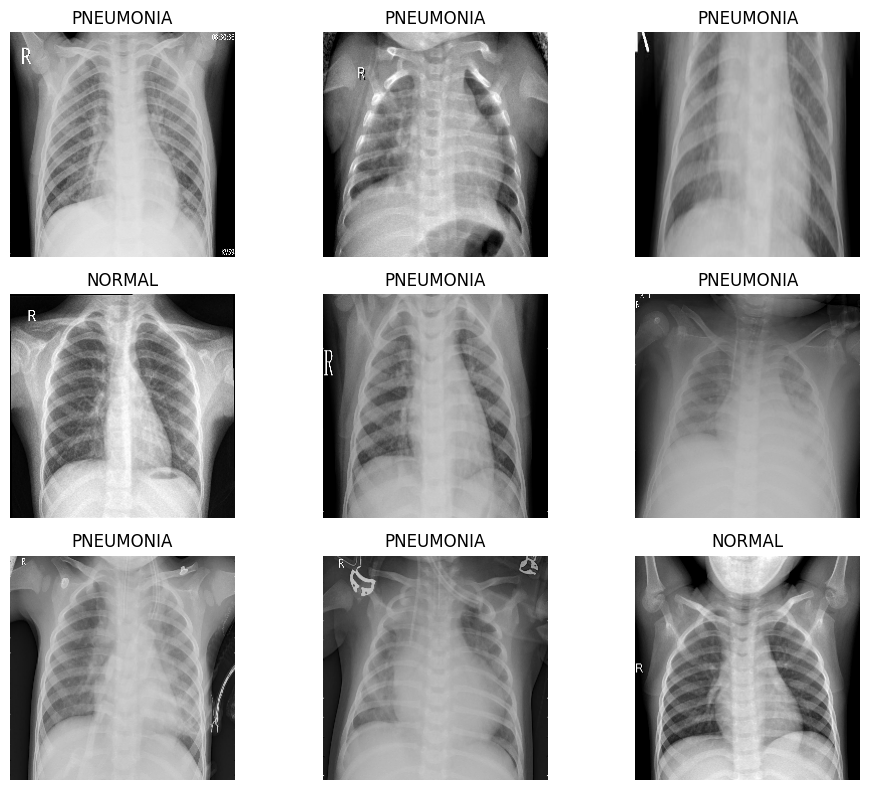

In [37]:
class_names = train_ds.class_names
for images, labels in train_ds.take(1):
    plt.figure(figsize=(10,8))
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(
            images[i].numpy().squeeze(),
            cmap="gray"
        )
        label = int(labels[i])
        plt.title(class_names[label])
        plt.axis("off")

plt.tight_layout()
plt.show()      


In [39]:
def datasets_to_tensors(dataset):
    images = []
    labels = []
    for batch_images, batch_labels in dataset:
        images.append(batch_images)
        labels.append(batch_labels)

    images = tf.concat(images,axis=0) 
    labels = tf.concat(labels,axis=0)   

    return images,labels

train_images, train_labels = datasets_to_tensors(train_ds)
test_images, test_labels = datasets_to_tensors(test_ds)
val_images, val_labels = datasets_to_tensors(val_ds)




In [43]:
print(f"train images shape: {train_images.shape}")
print(f"test images shape: {test_images.shape}")
print(f"validation images shape: {val_images.shape}")

train images shape: (5216, 224, 224, 1)
test images shape: (624, 224, 224, 1)
validation images shape: (16, 224, 224, 1)


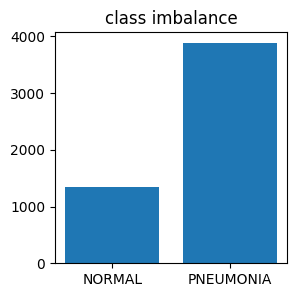

In [ ]:
normal = 0 
pneumonia = 0
for i in train_labels:
    if i == 0: normal += 1
    if i == 1: pneumonia += 1

values = [normal,pneumonia]  
plt.figure(figsize=(3,3))
plt.bar(class_names,values)
plt.title("class imbalance")
plt.show()
    